In [ ]:
import pandas as pd
from pathlib import Path

DATA_PATH = Path("../data/raw/online_retail_II.xlsx")

# Check whether the file exists
print("File exists:", DATA_PATH.exists())

# Inspect the workbook's sheet names
excel_file = pd.ExcelFile(DATA_PATH)

print("Sheets:", excel_file.sheet_names)

In [ ]:
for sheet in excel_file.sheet_names:
    print(f"\n--- {sheet} ---")

    sample = pd.read_excel(
        DATA_PATH,
        sheet_name=sheet,
        nrows=5
    )

    print(sample)
    print("\nColumns:", sample.columns.tolist())
    print("\nData types:")
    print(sample.dtypes)

In [ ]:
import pandas as pd
from pathlib import Path

DATA_PATH = Path("../data/raw/online_retail_II.xlsx")

# Read both sheets
df_2009 = pd.read_excel(
    DATA_PATH,
    sheet_name="Year 2009-2010"
)

df_2010 = pd.read_excel(
    DATA_PATH,
    sheet_name="Year 2010-2011"
)

# Combine them vertically
df = pd.concat(
    [df_2009, df_2010],
    ignore_index=True
)

print("Combined dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

df.head()

In [ ]:
# Dataset dimensions
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

# Column data types and non-null counts
df.info()

# Statistical summary of numeric columns
display(df.describe())

# First and last few records
display(df.head())
display(df.tail())

In [ ]:
# Missing values per column
missing = df.isnull().sum()

missing_report = pd.DataFrame({
    "missing_count": missing,
    "missing_percentage": (missing / len(df) * 100).round(2)
})

display(
    missing_report.sort_values(
        "missing_percentage",
        ascending=False
    )
)

# Exact duplicate rows
print("Exact duplicate rows:", df.duplicated().sum())

# Missing customer IDs
print("Missing Customer IDs:", df["Customer ID"].isnull().sum())

# Unique customers with an available ID
print("Unique customers:", df["Customer ID"].nunique())

In [ ]:
# Negative and zero quantities
print("Negative quantities:", (df["Quantity"] < 0).sum())
print("Zero quantities:", (df["Quantity"] == 0).sum())

# Negative, zero and positive prices
print("Negative prices:", (df["Price"] < 0).sum())
print("Zero prices:", (df["Price"] == 0).sum())
print("Positive prices:", (df["Price"] > 0).sum())

# Invoice numbers beginning with C may indicate cancellations
invoice_text = df["Invoice"].astype("string").str.strip()

cancelled_mask = invoice_text.str.startswith(
    "C",
    na=False
)

print("Rows with cancellation-style invoice IDs:", cancelled_mask.sum())

# Date range
print("Earliest invoice date:", df["InvoiceDate"].min())
print("Latest invoice date:", df["InvoiceDate"].max())

In [ ]:
audit_report = pd.DataFrame({
    "column": df.columns,
    "dtype": [str(dtype) for dtype in df.dtypes],
    "missing_count": df.isnull().sum().values,
    "missing_percentage": (
        df.isnull().mean().values * 100
    ).round(2)
})

audit_report.to_csv(
    "../reports/data_quality_audit.csv",
    index=False
)

print("Audit report saved.")

In [ ]:
import pandas as pd
from pathlib import Path

# Keep the original df unchanged
df_clean = df.copy()

# Standardize column names
df_clean.columns = df_clean.columns.str.strip()

# Remove extra spaces from text columns
for col in ["Invoice", "StockCode", "Description", "Country"]:
    df_clean[col] = df_clean[col].astype("string").str.strip()

# Convert numeric columns safely
df_clean["Quantity"] = pd.to_numeric(
    df_clean["Quantity"], errors="coerce"
)

df_clean["Price"] = pd.to_numeric(
    df_clean["Price"], errors="coerce"
)

df_clean["Customer ID"] = pd.to_numeric(
    df_clean["Customer ID"], errors="coerce"
)

# Parse dates
df_clean["InvoiceDate"] = pd.to_datetime(
    df_clean["InvoiceDate"], errors="coerce"
)

print("Working copy shape:", df_clean.shape)
print("Invalid dates:", df_clean["InvoiceDate"].isna().sum())
print("Invalid quantities:", df_clean["Quantity"].isna().sum())
print("Invalid prices:", df_clean["Price"].isna().sum())

df_clean.head()

In [ ]:
# Count exact duplicate rows
duplicate_count = df_clean.duplicated().sum()
print("Exact duplicate rows:", duplicate_count)

# Inspect some examples
duplicate_examples = df_clean[
    df_clean.duplicated(keep=False)
].sort_values(
    ["Invoice", "StockCode", "InvoiceDate"]
)

display(duplicate_examples.head(20))

In [ ]:
invoice_text = df_clean["Invoice"].astype("string").str.strip()

# Cancellation-style invoice identifier
df_clean["is_cancellation_invoice"] = (
    invoice_text.str.startswith("C", na=False)
)

# Financial value of each line, before considering returns
df_clean["line_value"] = (
    df_clean["Quantity"] * df_clean["Price"]
)

# Basic indicators
df_clean["is_negative_quantity"] = (
    df_clean["Quantity"] < 0
)

df_clean["is_nonpositive_price"] = (
    df_clean["Price"] <= 0
)

# Missing customer identifiers
df_clean["has_customer_id"] = (
    df_clean["Customer ID"].notna()
)

display(
    df_clean[
        [
            "Invoice",
            "Quantity",
            "Price",
            "line_value",
            "is_cancellation_invoice",
            "is_negative_quantity",
            "is_nonpositive_price",
            "has_customer_id",
        ]
    ].head(10)
)

In [ ]:
print(
    "Cancellation-style invoices:",
    df_clean["is_cancellation_invoice"].sum()
)

print(
    "Negative quantity rows:",
    df_clean["is_negative_quantity"].sum()
)

print(
    "Nonpositive price rows:",
    df_clean["is_nonpositive_price"].sum()
)

print(
    "Missing customer IDs:",
    df_clean["Customer ID"].isna().sum()
)

In [ ]:
purchase_mask = (
    df_clean["has_customer_id"]
    & df_clean["InvoiceDate"].notna()
    & df_clean["Quantity"].gt(0)
    & df_clean["Price"].gt(0)
    & ~df_clean["is_cancellation_invoice"]
)

purchases = df_clean.loc[purchase_mask].copy()

print("All transaction rows:", len(df_clean))
print("Preliminary purchase rows:", len(purchases))
print("Distinct customers:", purchases["Customer ID"].nunique())
print(
    "Purchase date range:",
    purchases["InvoiceDate"].min(),
    "to",
    purchases["InvoiceDate"].max()
)

purchases.head()

In [ ]:
customer_summary = (
    purchases.groupby("Customer ID")
    .agg(
        first_purchase=("InvoiceDate", "min"),
        last_purchase=("InvoiceDate", "max"),
        total_orders=("Invoice", "nunique"),
        total_items=("Quantity", "sum"),
        total_spend=("line_value", "sum"),
        distinct_products=("StockCode", "nunique"),
    )
    .reset_index()
)

customer_summary["days_between_first_and_last"] = (
    customer_summary["last_purchase"]
    - customer_summary["first_purchase"]
).dt.days

display(customer_summary.head(10))

In [ ]:
# 1. Count exact duplicates
print("Exact duplicate rows:", df_clean.duplicated().sum())

# 2. Inspect duplicate groups
duplicate_rows = df_clean[
    df_clean.duplicated(keep=False)
].copy()

display(
    duplicate_rows.sort_values(
        ["Invoice", "StockCode", "InvoiceDate"]
    ).head(30)
)

# 3. Check whether duplicate rows share the same invoice
duplicate_invoice_summary = (
    duplicate_rows.groupby("Invoice")
    .size()
    .sort_values(ascending=False)
)

display(duplicate_invoice_summary.head(10))

In [ ]:
# Unique customers and invoices
print("Customers:", purchases["Customer ID"].nunique())
print("Invoices:", purchases["Invoice"].nunique())

# Check if one invoice has multiple invoice dates
invoice_date_check = (
    purchases.groupby("Invoice")["InvoiceDate"]
    .nunique()
)

print(
    "Invoices with multiple dates:",
    (invoice_date_check > 1).sum()
)

# Check whether customers have purchases on the same date
purchases["purchase_date"] = (
    purchases["InvoiceDate"].dt.date
)

print(
    "Customer-date combinations:",
    purchases.groupby(
        ["Customer ID", "purchase_date"]
    ).ngroups
)

In [ ]:
# Find invoices with more than one distinct date
invoice_date_check = (
    purchases.groupby("Invoice")["InvoiceDate"]
    .nunique()
)

multiple_date_invoices = invoice_date_check[
    invoice_date_check > 1
].index

# Inspect their transaction rows
invoice_date_issues = purchases[
    purchases["Invoice"].isin(multiple_date_invoices)
].sort_values(["Invoice", "InvoiceDate"])

display(invoice_date_issues.head(50))

In [ ]:
# Summary of the affected invoices
display(
    invoice_date_issues.groupby("Invoice").agg(
        date_count=("InvoiceDate", "nunique"),
        customer_count=("Customer ID", "nunique"),
        row_count=("Invoice", "size"),
        first_date=("InvoiceDate", "min"),
        last_date=("InvoiceDate", "max")
    ).head(20)
)

In [ ]:
invoice_audit = (
    purchases.groupby("Invoice")
    .agg(
        date_count=("InvoiceDate", "nunique"),
        customer_count=("Customer ID", "nunique"),
        row_count=("Invoice", "size"),
        first_date=("InvoiceDate", "min"),
        last_date=("InvoiceDate", "max"),
    )
    .reset_index()
)

# Inspect invoices with multiple timestamps
multiple_dates = invoice_audit[
    invoice_audit["date_count"] > 1
]

print("Invoices with multiple timestamps:", len(multiple_dates))

print(
    "Invoices linked to multiple customers:",
    (multiple_dates["customer_count"] > 1).sum()
)

display(multiple_dates.head(20))

In [ ]:
invoice_level = (
    purchases.groupby(["Invoice", "Customer ID"])
    .agg(
        invoice_date=("InvoiceDate", "min"),
        invoice_value=("line_value", "sum"),
        total_quantity=("Quantity", "sum"),
        distinct_products=("StockCode", "nunique"),
    )
    .reset_index()
)

print("Invoice-level rows:", len(invoice_level))
print("Unique invoice IDs:", invoice_level["Invoice"].nunique())
print("Unique customers:", invoice_level["Customer ID"].nunique())

display(invoice_level.head(10))

In [ ]:
# Check whether each invoice belongs to one customer
invoice_customer_counts = (
    invoice_level.groupby("Invoice")["Customer ID"].nunique()
)

print(
    "Invoices linked to multiple customers:",
    (invoice_customer_counts > 1).sum()
)

# Check for duplicate invoice-customer combinations
print(
    "Duplicate invoice-customer rows:",
    invoice_level.duplicated(
        subset=["Invoice", "Customer ID"]
    ).sum()
)

# Check invalid invoice totals
print("Nonpositive invoice values:", (invoice_level["invoice_value"] <= 0).sum())
print("Missing invoice dates:", invoice_level["invoice_date"].isna().sum())

display(invoice_level.describe())

In [ ]:
invoice_customer_counts = (
    invoice_level.groupby("Invoice")["Customer ID"].nunique()
)

print(
    "Invoices linked to multiple customers:",
    (invoice_customer_counts > 1).sum()
)

print(
    "Duplicate invoice-customer rows:",
    invoice_level.duplicated(
        subset=["Invoice", "Customer ID"]
    ).sum()
)

print(
    "Nonpositive invoice values:",
    (invoice_level["invoice_value"] <= 0).sum()
)

print(
    "Missing invoice dates:",
    invoice_level["invoice_date"].isna().sum()
)

In [ ]:
from pathlib import Path

output_path = Path("../data/processed/invoice_level.csv")
output_path.parent.mkdir(parents=True, exist_ok=True)

invoice_level.to_csv(output_path, index=False)

print("Saved to:", output_path.resolve())
print("Rows exported:", len(invoice_level))

In [ ]:
print(invoice_level.columns.tolist())

In [ ]:
import pandas as pd
from pathlib import Path

DATA_PATH = Path("../data/raw/online_retail_II.xlsx")

# Read both sheets
df_2009 = pd.read_excel(
    DATA_PATH,
    sheet_name="Year 2009-2010"
)

df_2010 = pd.read_excel(
    DATA_PATH,
    sheet_name="Year 2010-2011"
)

# Combine them vertically
df = pd.concat(
    [df_2009, df_2010],
    ignore_index=True
)

print("Combined dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

df.head()

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Work on a copy
monthly_data = invoice_level.copy()

# Standardize column names
monthly_data.columns = (
    monthly_data.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

print("Columns:", monthly_data.columns.tolist())

# Ensure date column is datetime
monthly_data["invoice_date"] = pd.to_datetime(
    monthly_data["invoice_date"]
)

# Create monthly revenue, orders and customer metrics
monthly_data["month"] = (
    monthly_data["invoice_date"].dt.to_period("M")
)

monthly = (
    monthly_data.groupby("month")
    .agg(
        revenue=("invoice_value", "sum"),
        orders=("invoice", "nunique"),
        customers=("customer_id", "nunique")
    )
    .reset_index()
)

monthly["month"] = monthly["month"].astype(str)

# Plot monthly revenue
plt.figure(figsize=(12, 5))
plt.plot(monthly["month"], monthly["revenue"], marker="o")
plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=60)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

display(monthly.head())

In [ ]:
fig, ax1 = plt.subplots(figsize=(12, 5))

ax1.plot(
    monthly["month"],
    monthly["revenue"],
    marker="o",
    label="Revenue"
)
ax1.set_xlabel("Month")
ax1.set_ylabel("Revenue")

ax2 = ax1.twinx()
ax2.plot(
    monthly["month"],
    monthly["customers"],
    marker="s",
    linestyle="--",
    label="Active customers"
)
ax2.set_ylabel("Active customers")

plt.title("Monthly Revenue vs Active Customers")
plt.xticks(rotation=60)
fig.tight_layout()
plt.show()

In [ ]:
df = pd.read_csv("../data/processed/churn_training_data.csv")
print(df.shape)

In [ ]:
# 1. Inspect column types and missing values
df.info()

print("\nMissing values:")
print(df.isnull().sum())

# 2. Check duplicates
print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate customer IDs:", df["customer_id"].duplicated().sum())

# 3. Inspect numerical statistics
display(df.describe().round(2))

In [ ]:
print("Churn counts:")
print(df["churn_label"].value_counts().sort_index())

print("\nChurn percentages:")
print((df["churn_label"].value_counts(normalize=True).sort_index() * 100).round(2))

In [ ]:
# Check dataset structure
print("Dataset shape:", df.shape)
df.info()

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# Check duplicates
print("\nDuplicate rows:", df.duplicated().sum())
print(
    "Duplicate customer IDs:",
    df["customer_id"].duplicated().sum()
)

# Summary statistics
display(df.describe().round(2))

In [ ]:
import matplotlib.pyplot as plt

# Customer spending distribution
plt.figure(figsize=(8, 5))
plt.hist(df["spend_90d"], bins=50)
plt.xlabel("Spending in 90 days")
plt.ylabel("Number of customers")
plt.title("Distribution of Customer Spending")
plt.tight_layout()
plt.show()

# Order frequency distribution
plt.figure(figsize=(8, 5))
df["orders_90d"].value_counts().sort_index().plot(kind="bar")
plt.xlabel("Number of orders")
plt.ylabel("Number of customers")
plt.title("Customer Order Frequency")
plt.tight_layout()
plt.show()

# Churn rate by label
print(df["churn_label"].value_counts(normalize=True).sort_index() * 100)

In [ ]:
# Compare features across churn groups
summary = (
    df.groupby("churn_label")[
        ["orders_90d", "spend_90d", "quantity_90d", "recency_days"]
    ]
    .agg(["mean", "median"])
    .round(2)
)

display(summary)

In [ ]:
import matplotlib.pyplot as plt

features = ["orders_90d", "spend_90d", "quantity_90d", "recency_days"]

for feature in features:
    plt.figure(figsize=(7, 4))

    df.boxplot(column=feature, by="churn_label")

    plt.title(f"{feature} by Churn Label")
    plt.suptitle("")
    plt.xlabel("Churn label (0 = retained, 1 = churned)")
    plt.ylabel(feature)

    plt.tight_layout()
    plt.show()

In [60]:
features = [
    "orders_90d",
    "spend_90d",
    "quantity_90d",
    "recency_days"
]

group_means = df.groupby("churn_label")[features].mean()

comparison = pd.DataFrame({
    "Retained": group_means.loc[0],
    "Churned": group_means.loc[1]
})

comparison["Relative_difference_%"] = (
    (comparison["Churned"] - comparison["Retained"])
    / comparison["Retained"] * 100
).round(2)

display(comparison.round(2))

,Retained,Churned,Relative_difference_%
orders_90d,2.37,1.34,-43.65
spend_90d,1186.91,502.94,-57.63
quantity_90d,713.40,282.86,-60.35
recency_days,35.06,43.80,24.93


In [61]:
# Inspect data types
print(df.dtypes)

# Check for impossible or unexpected values
print("\nMinimum values:")
print(df[[
    "orders_90d",
    "spend_90d",
    "quantity_90d",
    "recency_days"
]].min())

# Check extreme values
print("\n99th percentile:")
print(
    df[[
        "orders_90d",
        "spend_90d",
        "quantity_90d",
        "recency_days"
    ]].quantile(0.99)
)

customer_id       int64
orders_90d        int64
spend_90d       float64
quantity_90d      int64
recency_days      int64
churn_label       int64
dtype: object

Minimum values:
orders_90d      1.0
spend_90d       5.9
quantity_90d    1.0
recency_days    1.0
dtype: float64

99th percentile:
orders_90d        11.0000
spend_90d       9089.5768
quantity_90d    6236.6400
recency_days      88.0000
Name: 0.99, dtype: float64


,customers,churn_rate
recency_group,,
1–15,515,24.08
16–30,397,26.45
31–45,325,29.54
46–60,246,40.65
61–75,202,44.55
76–90,238,41.18


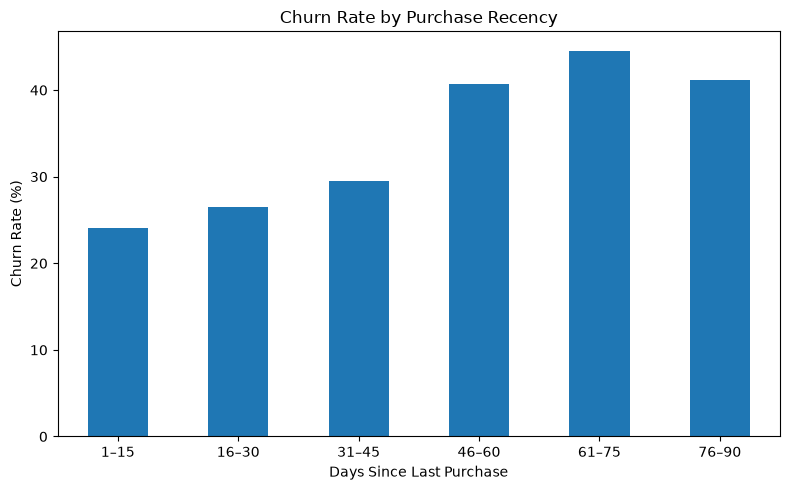

In [62]:
import pandas as pd
import matplotlib.pyplot as plt

df["recency_group"] = pd.cut(
    df["recency_days"],
    bins=[0, 15, 30, 45, 60, 75, 90],
    labels=["1–15", "16–30", "31–45", "46–60", "61–75", "76–90"]
)

recency_analysis = (
    df.groupby("recency_group", observed=False)
      .agg(
          customers=("churn_label", "size"),
          churn_rate=("churn_label", "mean")
      )
)

recency_analysis["churn_rate"] *= 100

display(recency_analysis.round(2))

recency_analysis["churn_rate"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Churn Rate by Purchase Recency")
plt.xlabel("Days Since Last Purchase")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()